In [1]:
import pandas as pd

In [4]:
!python -m pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
!python -m pip install seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
import matplotlib.pyplot as plt
import seaborn as sns

In [47]:
df1 = pd.read_csv(r'D:\avin proj\aavin_sales_data.csv')

In [48]:
df=pd.DataFrame(df1)

In [49]:
df

,order_id,order_date,district,outlet_type,product_name,category,unit_price,quantity_sold,revenue,payment_mode
0,AV006163,2025-09-02,Cuddalore,retail shop,Milk Powder 500g,MILK POWDER,216.73,20.0,4334.60,UPI
1,AV006412,2024-05-19,THANJAVUR,Aavin Parlour,Ghee 1L,Ghee,NaN,15.0,9606.30,CARD
2,AV003547,2024-01-03,Chennai,Aavin Parlour,Butter Milk 200ml,butter milk,10.58,52.0,550.16,Card
3,AV001512,2025-08-17,Vellore,Aavin Parlour,Milk Powder 500g,Milk Powder,210.56,13.0,2737.28,Cash
4,AV003222,2024-04-21,Coimbatore,retail shop,Ice Cream Cup 100ml,Ice Cream,31.04,15.0,465.60,UPI
...,...,...,...,...,...,...,...,...,...,...
8075,AV005461,2024-02-25,Coimbatore,Aavin Parlour,Butter Milk 200ml,BUTTER MILK,9.84,45.0,442.80,CASH
8076,AV001658,2023-08-23,Coimbatore,Aavin Parlour,Paneer 200g,Paneer,85.15,17.0,1447.55,Cash
8077,AV006943,2024-07-20,Tirunelveli,super market,Ghee 500ml,Ghee,307.07,17.0,5220.19,CARD
8078,AV006571,2023-11-07,Dindigul,Super Market,Sweets - Peda 250g,Sweets,129.11,18.0,2323.98,card


In [50]:
df.columns

Index(['order_id', 'order_date', 'district', 'outlet_type', 'product_name',
       'category', 'unit_price', 'quantity_sold', 'revenue', 'payment_mode'],
      dtype='str')

In [51]:
df.shape

(8080, 10)

In [52]:
df.describe()

,unit_price,quantity_sold,revenue
count,7840.000000,7840.000000,8080.000000
mean,160.151130,18.170153,1558.755470
std,748.792488,14.938933,2124.236209
min,9.500000,-55.000000,28.500000
25%,28.130000,8.000000,392.295000
50%,47.870000,15.000000,806.875000
75%,128.240000,24.000000,1641.695000
max,30698.500000,60.000000,13329.400000


In [53]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8080 entries, 0 to 8079
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       8080 non-null   str    
 1   order_date     8080 non-null   str    
 2   district       7838 non-null   str    
 3   outlet_type    8080 non-null   str    
 4   product_name   8080 non-null   str    
 5   category       8080 non-null   str    
 6   unit_price     7840 non-null   float64
 7   quantity_sold  7840 non-null   float64
 8   revenue        8080 non-null   float64
 9   payment_mode   7839 non-null   str    
dtypes: float64(3), str(7)
memory usage: 631.4 KB


In [54]:
df.duplicated().sum()

np.int64(77)

In [55]:
df=df.drop_duplicates()

In [59]:
df['order_date'] = pd.to_datetime(
    df['order_date'],
    errors='coerce'
)

In [60]:
df=df.dropna(subset=['order_date'])

In [61]:
df.isnull().sum()

order_id           0
order_date         0
district         241
outlet_type        0
product_name       0
category           0
unit_price       238
quantity_sold    237
revenue            0
payment_mode     240
dtype: int64

{'whiskers': [<matplotlib.lines.Line2D at 0x2071c24a7b0>,
 'caps': [<matplotlib.lines.Line2D at 0x2071c24aa50>,
 'boxes': [<matplotlib.lines.Line2D at 0x2071c24a660>],
 'medians': [<matplotlib.lines.Line2D at 0x2071c24acf0>],
 'fliers': [<matplotlib.lines.Line2D at 0x2071c24ae40>],
 'means': []}

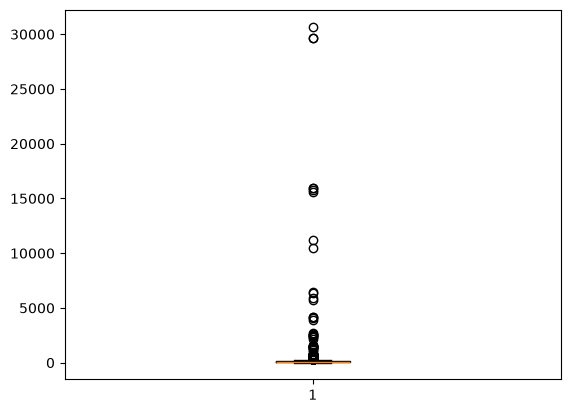

In [74]:
plt.boxplot(df['unit_price'].dropna())

{'whiskers': [<matplotlib.lines.Line2D at 0x2071c4757f0>,
 'caps': [<matplotlib.lines.Line2D at 0x2071c475550>,
 'boxes': [<matplotlib.lines.Line2D at 0x2071c475160>],
 'medians': [<matplotlib.lines.Line2D at 0x2071c475a90>],
 'fliers': [<matplotlib.lines.Line2D at 0x2071c475940>],
 'means': []}

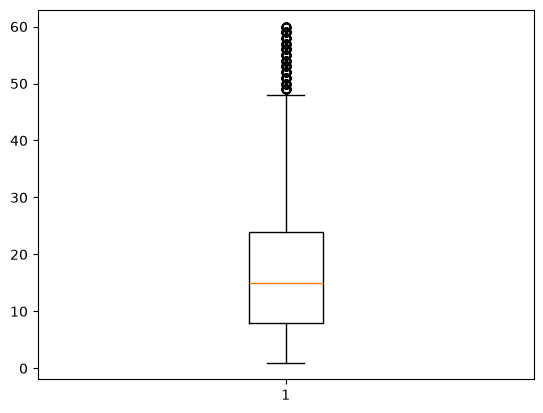

In [71]:
plt.boxplot(df['quantity_sold'].dropna())

In [68]:
df['quantity_sold']=df['quantity_sold'].abs()

In [70]:
df['quantity_sold']=df['quantity_sold'].fillna(df['quantity_sold'].median())

In [72]:
df['unit_price']=df['unit_price'].fillna(df['unit_price'].median())

In [75]:
 df=df.dropna(subset=['district','payment_mode'])

In [76]:
df.isnull().sum()

order_id         0
order_date       0
district         0
outlet_type      0
product_name     0
category         0
unit_price       0
quantity_sold    0
revenue          0
payment_mode     0
dtype: int64

In [80]:
text_cols={
    "district","outlet_type","product_name","category","payment_mode"
}

In [85]:
for col in text_cols:
    df[col]=df[col].astype(str).str.strip().str.title()

In [84]:
for col in text_cols:
    print(col)
    print(df[col].unique())
    print()

product_name
<StringArray>
[     'Milk Powder 500G',               'Ghee 1L',     'Butter Milk 200Ml',
   'Ice Cream Cup 100Ml',      'Toned Milk 500Ml',    'Sweets - Peda 250G',
             'Curd 400G',            'Ghee 500Ml',           'Butter 100G',
           'Paneer 200G',             'Curd 200G',         'Toned Milk 1L',
 'Full Cream Milk 500Ml']
Length: 13, dtype: str

payment_mode
<StringArray>
['Upi', 'Card', 'Cash', 'Wallet']
Length: 4, dtype: str

category
<StringArray>
['Milk Powder',        'Ghee', 'Butter Milk',   'Ice Cream',        'Milk',
      'Sweets',        'Curd',      'Butter',      'Paneer']
Length: 9, dtype: str

outlet_type
<StringArray>
['Retail Shop', 'Aavin Parlour', 'Milk Booth', 'Super Market',
 'Online Delivery']
Length: 5, dtype: str

district
<StringArray>
[  'Cuddalore',   'Thanjavur',     'Chennai',     'Vellore',  'Coimbatore',
       'Erode',      'Trichy',       'Salem', 'Tirunelveli',    'Dindigul',
 'Kanchipuram',     'Madurai']
Length: 12, dt

In [88]:
df.shape


(7526, 10)

In [89]:
df.duplicated().sum()

np.int64(0)

In [90]:
df.isnull().sum()

order_id         0
order_date       0
district         0
outlet_type      0
product_name     0
category         0
unit_price       0
quantity_sold    0
revenue          0
payment_mode     0
dtype: int64

In [92]:
df.info()

<class 'pandas.DataFrame'>
Index: 7526 entries, 0 to 8079
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       7526 non-null   str           
 1   order_date     7526 non-null   datetime64[us]
 2   district       7526 non-null   str           
 3   outlet_type    7526 non-null   str           
 4   product_name   7526 non-null   str           
 5   category       7526 non-null   str           
 6   unit_price     7526 non-null   float64       
 7   quantity_sold  7526 non-null   float64       
 8   revenue        7526 non-null   float64       
 9   payment_mode   7526 non-null   str           
dtypes: datetime64[us](1), float64(3), str(6)
memory usage: 646.8 KB


In [94]:
df['month']=df['order_date'].dt.to_period('M')
df['year']=df['order_date'].dt.year

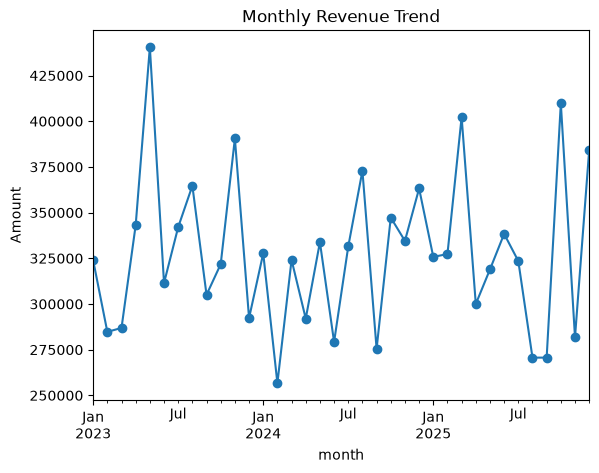

In [96]:
df.groupby('month')['revenue'].sum().plot(kind='line', marker='o')
plt.title('Monthly Revenue Trend')
plt.ylabel('Amount')
plt.show()

In [99]:
df['outlet_type']

0         Retail Shop
1       Aavin Parlour
2       Aavin Parlour
3       Aavin Parlour
4         Retail Shop
            ...      
8075    Aavin Parlour
8076    Aavin Parlour
8077     Super Market
8078     Super Market
8079    Aavin Parlour
Name: outlet_type, Length: 7526, dtype: str

<Figure size 2000x2000 with 0 Axes>

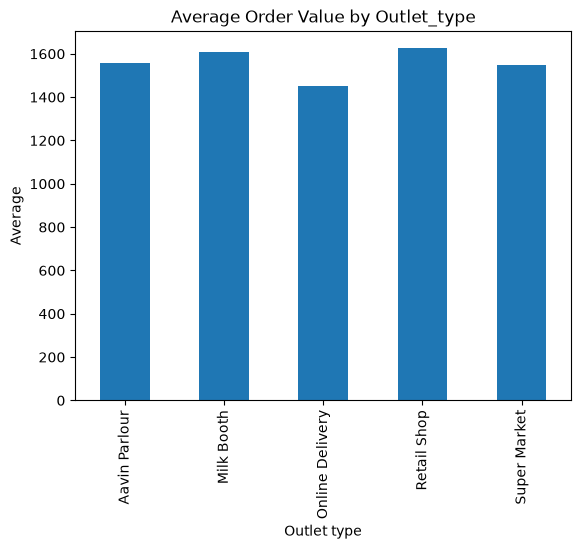

In [111]:
df2=df.groupby('outlet_type')['revenue'].agg('mean').plot(kind='bar')
plt.title('Average Order Value by Outlet_type')
plt.xlabel('Outlet type')
plt.ylabel('Average')
plt.Figure(figsize=(20,20))

In [112]:
df.columns

Index(['order_id', 'order_date', 'district', 'outlet_type', 'product_name',
       'category', 'unit_price', 'quantity_sold', 'revenue', 'payment_mode',
       'month', 'year'],
      dtype='str')

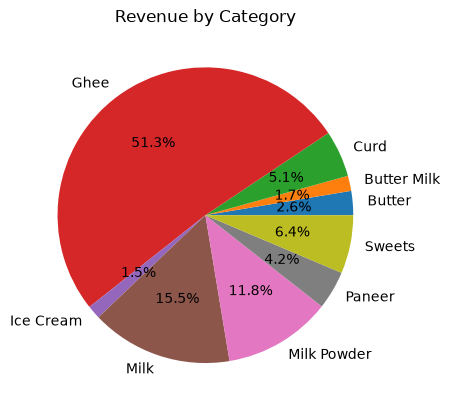

In [122]:
df.groupby('category')['revenue'].sum().plot(kind='pie',autopct='%1.1f%%')
plt.title('Revenue by Category')
plt.show()

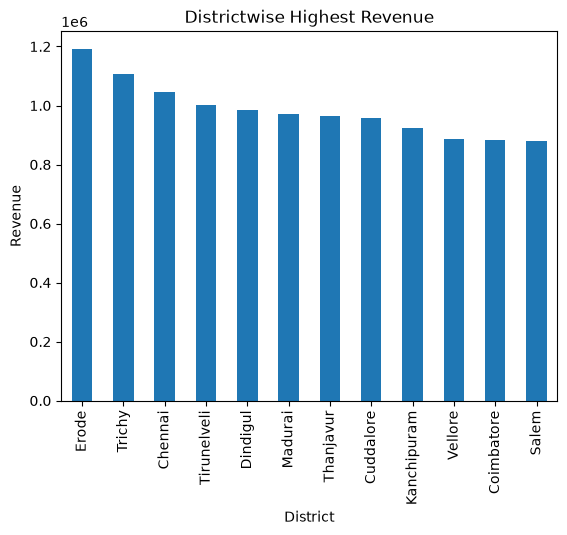

In [128]:
district_rev = df.groupby('district')['revenue'].sum().sort_values(ascending=False)
district_rev.plot(kind='bar')
plt.title("Districtwise Highest Revenue")
plt.xlabel("District")
plt.ylabel("Revenue")
plt.show()

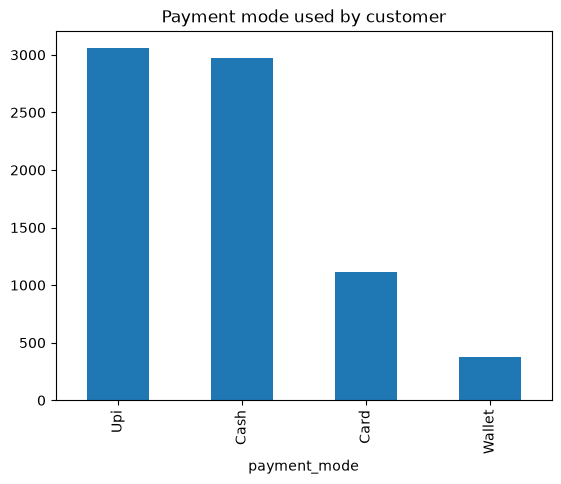

In [130]:
payment=df['payment_mode'].value_counts()
payment.plot(kind='bar')
plt.title("Payment mode used by customer")
plt.show()
